# 05 · Feature Engineering and Weight of Evidence

| | |
|---|---|
| **Question** | Which variables carry real, stable signal, and how should they be encoded for a transparent scorecard? |
| **Inputs** | Cleaned train (2012 to 2014) and validation (2015) splits |
| **Outputs** | `models/woe_binning.json` (bins and WoE for every variable), the final scorecard variable list |
| **Skills shown** | Monotonic binning, Weight of Evidence, Information Value, correlation pruning, Population Stability Index |

### Why Weight of Evidence?

Banks build application scorecards on WoE-encoded variables because the result can be read by a credit committee and a regulator:

| Property | Benefit |
|---|---|
| Every variable becomes a small number of bins | A credit officer can read the scorecard as a table of points |
| Bad rate is forced to move in one direction across bins | The model can never reward a borrower for becoming riskier |
| Missing values get their own bin | "Not reported" carries its own measured risk instead of a guessed value |
| Non-linear relationships are captured by the bins | A linear model on WoE inputs handles curved risk patterns |
| Outliers fall into the end bins | Extreme values cannot dominate the model |

**Definitions** (target = 1 for bad):

$$WoE_i = \ln\left(\frac{\%\,\text{goods in bin } i}{\%\,\text{bads in bin } i}\right) \qquad IV = \sum_i (\%\,\text{goods}_i - \%\,\text{bads}_i) \times WoE_i$$

Positive WoE means safer than average; negative means riskier. The binning algorithm lives in `src/meridian/features/woe.py`: 20 initial quantile bins, merge adjacent bins until bad rates are monotonic, then merge until every bin holds at least 5% of loans and there are at most 8 bins.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from meridian import config, viz
from meridian.data import TARGET
from meridian.features.cleaning import FEATURES_CATEGORICAL, FEATURES_NUMERIC
from meridian.features.woe import WoEBinner, psi

viz.set_style()
FEATURES_DIR = config.DATA_DIR / "features"
MODELS_DIR = config.PROJECT_ROOT / "models"
train = pd.read_parquet(FEATURES_DIR / "pd_train.parquet")
valid = pd.read_parquet(FEATURES_DIR / "pd_validation.parquet")
y_train = train[TARGET].astype(float)
y_valid = valid[TARGET].astype(float)

numeric = [c for c in FEATURES_NUMERIC if c not in ("is_joint_application", "term_months")]
categorical = FEATURES_CATEGORICAL + ["term_months"]
print(f"Candidate variables: {len(numeric)} numeric + {len(categorical)} categorical = {len(numeric) + len(categorical)}")

Candidate variables: 42 numeric + 5 categorical = 47


`is_joint_application` is excluded because it is constant in the training period (joint applications started in 2015). `term_months` has only two values, so it is binned as a category.

## 1. Fit the bins on train

In [2]:
binner = WoEBinner(max_bins=8, initial_bins=20, min_bin_share=0.05).fit(train, y_train, numeric, categorical)
iv = binner.iv_table()
iv.style.format({"iv": "{:.4f}"}).hide(axis="index").bar(subset=["iv"], color="#9ec5f4", vmin=0)

variable,kind,bins,iv,strength
fico_score,numeric,8,0.1014,Medium
payment_to_income,numeric,8,0.0801,Weak
accounts_opened_24m,numeric,8,0.0757,Weak
loan_to_income,numeric,8,0.0702,Weak
accounts_opened_12m,numeric,6,0.0623,Weak
annual_income,numeric,8,0.0578,Weak
bankcard_open_to_buy,numeric,8,0.0503,Weak
debt_to_income,numeric,8,0.0491,Weak
months_since_recent_account,numeric,8,0.0446,Weak
months_since_recent_inquiry,numeric,9,0.0441,Weak


## 2. Reading a binning table

Two examples show what the algorithm produced.

In [3]:
def show_bins(var):
    t = pd.DataFrame(binner.binnings_[var].table)
    t["share"] = t.loans / t.loans.sum()
    return t[["bin", "loans", "share", "bad_rate", "woe", "iv"]].style.format(
        {"loans": "{:,.0f}", "share": "{:.1%}", "bad_rate": "{:.2%}", "woe": "{:+.3f}", "iv": "{:.4f}"}
    ).hide(axis="index").set_caption(f"{var}   (IV = {binner.binnings_[var].iv:.4f})")

show_bins("fico_score")

bin,loans,share,bad_rate,woe,iv
"[-inf, 667)","36,225",8.5%,12.22%,-0.347,0.0119
"[667, 672)","36,762",8.7%,11.70%,-0.297,0.0087
"[672, 677)","37,706",8.9%,11.47%,-0.275,0.0075
"[677, 687)","68,321",16.1%,10.50%,-0.176,0.0054
"[687, 697)","60,802",14.3%,9.47%,-0.061,0.0006
"[697, 712)","72,840",17.2%,7.94%,+0.132,0.0028
"[712, 737)","67,399",15.9%,6.42%,+0.360,0.0178
"[737, +inf)","43,755",10.3%,4.28%,+0.790,0.0468


In [4]:
show_bins('employment_years')

bin,loans,share,bad_rate,woe,iv
"[-inf, 1)","31,206",7.4%,10.22%,-0.146,0.0017
"[1, 2)","26,027",6.1%,9.26%,-0.036,0.0001
"[2, 10)","205,967",48.6%,9.12%,-0.019,0.0002
"[10, +inf)","140,704",33.2%,8.00%,+0.123,0.0048
Missing,"19,906",4.7%,11.73%,-0.301,0.0048


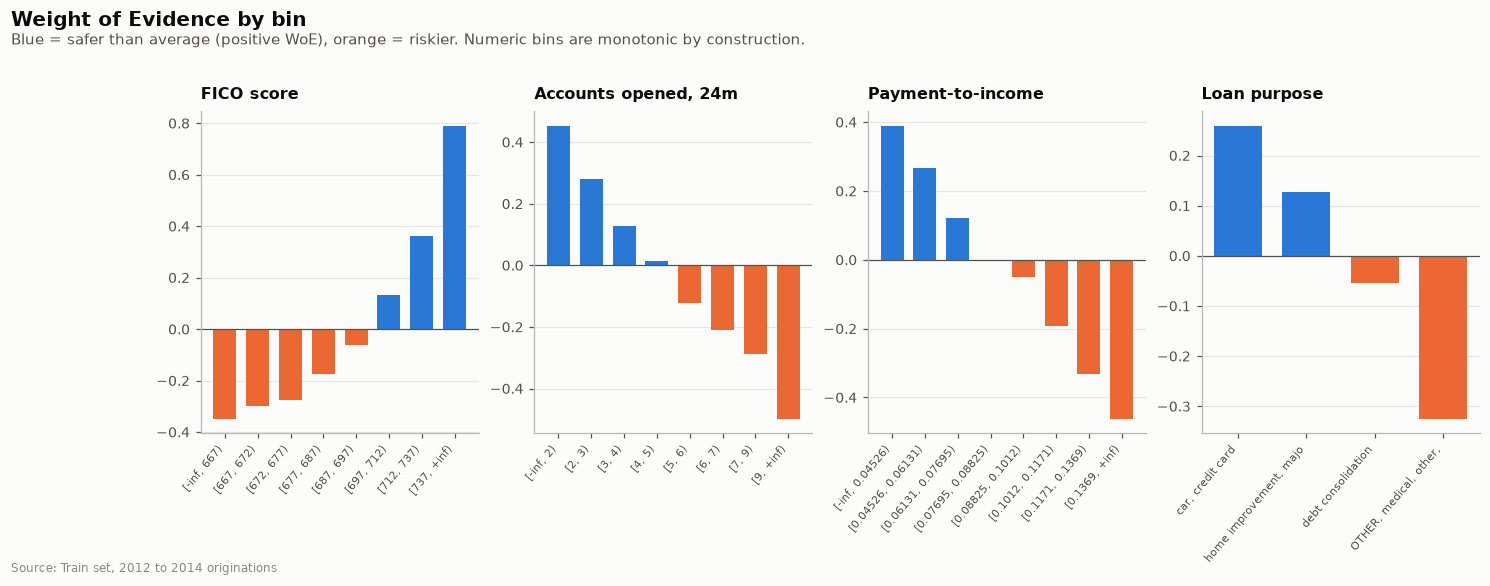

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, var, title in zip(axes, ["fico_score", "accounts_opened_24m", "payment_to_income", "loan_purpose"],
                          ["FICO score", "Accounts opened, 24m", "Payment-to-income", "Loan purpose"]):
    t = pd.DataFrame(binner.binnings_[var].table)
    colors = [viz.BLUE if w >= 0 else viz.ORANGE for w in t.woe]
    labels = t.bin.str.replace("_", " ").str.slice(0, 22)
    ax.bar(range(len(t)), t.woe, color=colors, width=0.7)
    ax.axhline(0, color=viz.INK_2, lw=0.8)
    ax.set_xticks(range(len(t)), labels, rotation=50, ha="right", fontsize=7.5)
    ax.set_title(title, fontsize=10.5, pad=8)
fig.suptitle("Weight of Evidence by bin", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.12)
fig.text(0.01, 1.04, "Blue = safer than average (positive WoE), orange = riskier. Numeric bins are monotonic by construction.",
         fontsize=9.5, color=viz.INK_2)
viz.source(fig, "Train set, 2012 to 2014 originations", y=-0.2)
plt.show()

**Reading the FICO table:** borrowers below 667 have a bad rate of 12.2% (WoE -0.35). Above 737 the bad rate drops to 4.3% (WoE +0.79). The bad rate falls in every step, with no reversals, so the scorecard will award more points at every higher FICO band.

**Reading the employment table:** the "Missing" bin (borrowers who did not state an employment length) has the most negative WoE (-0.30), riskier than any stated value. The audit finding from notebook 02 is now encoded directly. The separate `employment_not_stated` flag becomes redundant: at 4.7% of loans it falls below the 5% minimum bin size and collapses into one bin with IV 0. The same happens to other rare flags. Their information is carried by the missing bins of the original variables.

## 3. Selection step 1: Information Value

| IV | Strength | Decision |
|---|---|---|
| < 0.02 | Useless | Drop |
| 0.02 to 0.1 | Weak | Keep as candidate |
| 0.1 to 0.3 | Medium | Keep |
| > 0.5 | Suspicious | Investigate for leakage |

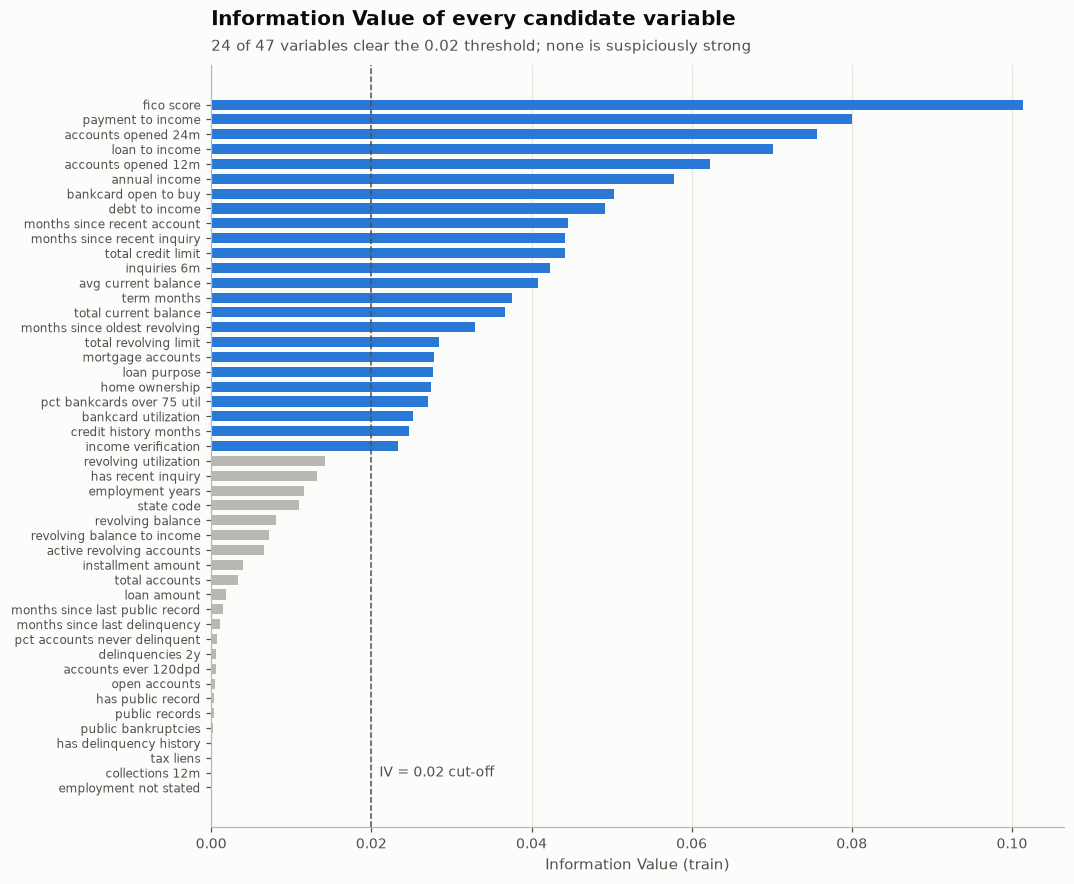

In [6]:
fig, ax = plt.subplots(figsize=(10, 9))
d = iv.iloc[::-1]
colors = [viz.BLUE if v >= 0.02 else viz.NEUTRAL for v in d.iv]
ax.barh(d.variable.str.replace("_", " "), d.iv, color=colors, height=0.68)
ax.axvline(0.02, color=viz.INK_2, lw=1, ls="--")
ax.text(0.0205, 1, " IV = 0.02 cut-off", fontsize=9, color=viz.INK_2, va="center")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="x", color=viz.GRID)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Information Value (train)")
ax.set_title("Information Value of every candidate variable")
viz.subtitle(ax, f"{(iv.iv >= 0.02).sum()} of {len(iv)} variables clear the 0.02 threshold; none is suspiciously strong")
plt.show()

**What it means:**

- **24 variables** carry at least weak signal. Only FICO reaches "medium" strength (IV 0.10). This is typical for a consumer lending book where the obviously bad applicants have already been declined. The remaining signal is spread across many modest variables.
- **No variable is "suspicious"** (IV > 0.5). The leakage controls from notebooks 01 and 02 worked.
- **Derogatory history** (delinquencies, public records, bankruptcies, collections) carries almost no IV. Lending Club's credit policy already filtered most of those borrowers out, so within the approved population these fields barely vary.

## 4. Selection step 2: remove redundancy

Two variables that encode the same information split the weight between them and make the coefficients unstable. Among any pair whose WoE values correlate above 0.7, the one with the lower IV is dropped.

In [7]:
candidates = iv.loc[iv.iv >= 0.02, "variable"].tolist()
W_train = binner.transform(train, candidates)
corr = W_train.corr().abs()

kept, dropped = [], []
for var in candidates:                       # already ordered by IV, highest first
    clash = [k for k in kept if corr.loc[var, k] > 0.7]
    if clash:
        dropped.append({"variable": var, "iv": binner.binnings_[var].iv,
                        "dropped_in_favour_of": clash[0], "woe_correlation": corr.loc[var, clash[0]]})
    else:
        kept.append(var)
print(f"Kept {len(kept)} of {len(candidates)}")
pd.DataFrame(dropped).style.format({"iv": "{:.4f}", "woe_correlation": "{:.2f}"}).hide(axis="index")

Kept 18 of 24


variable,iv,dropped_in_favour_of,woe_correlation
loan_to_income,0.0702,payment_to_income,0.93
inquiries_6m,0.0424,months_since_recent_inquiry,0.75
avg_current_balance,0.0409,total_credit_limit,0.84
total_current_balance,0.0366,total_credit_limit,0.95
bankcard_utilization,0.0252,bankcard_open_to_buy,0.72
credit_history_months,0.0247,months_since_oldest_revolving,0.83


## 5. Selection step 3: stability over time

A variable whose distribution or risk pattern changes between train and validation will make the scorecard drift. Two checks per variable:

1. **Population Stability Index (PSI)** of the bin shares, train versus validation. Below 0.1 is stable, 0.1 to 0.25 is a warning, above 0.25 is unstable.
2. **Trend consistency:** in validation, does the bad rate still move in the same direction across the bins? Measured by the rank correlation between train WoE and validation WoE per bin.

In [8]:
rows = []
for var in kept:
    vb = binner.binnings_[var]
    nb = len(vb.woe) + 1
    bt = np.bincount(binner.bin_index(train, var), minlength=nb)
    bv_idx = binner.bin_index(valid, var)
    bv = np.bincount(bv_idx, minlength=nb)
    keep_bins = (bt > 0) | (bv > 0)
    # Validation WoE per bin, using the validation population's own goods and bads.
    bad_v = np.bincount(bv_idx, weights=y_valid.to_numpy(), minlength=nb)
    good_v = bv - bad_v
    woe_v = np.log(((good_v + 0.5) / (good_v.sum() + 0.5 * nb)) / ((bad_v + 0.5) / (bad_v.sum() + 0.5 * nb)))
    woe_t = np.append(vb.woe, vb.woe_missing)
    mask = (bt > 0) & (bv > 0)
    trend = pd.Series(woe_t[mask]).corr(pd.Series(woe_v[mask]), method="spearman") if mask.sum() > 2 else 1.0
    iv_valid = float(np.sum(((good_v + 0.5) / (good_v.sum() + 0.5 * nb) - (bad_v + 0.5) / (bad_v.sum() + 0.5 * nb)) * woe_v))
    rows.append({"variable": var, "iv_train": vb.iv, "iv_validation": iv_valid,
                 "psi_train_vs_validation": psi(bt[keep_bins], bv[keep_bins]), "woe_trend_consistency": trend})
stab = pd.DataFrame(rows)
stab["status"] = np.where((stab.psi_train_vs_validation > 0.25) | (stab.woe_trend_consistency < 0.8), "Reject",
                 np.where(stab.psi_train_vs_validation > 0.1, "Monitor", "Stable"))
stab.style.format({"iv_train": "{:.4f}", "iv_validation": "{:.4f}", "psi_train_vs_validation": "{:.3f}",
                   "woe_trend_consistency": "{:.2f}"}).hide(axis="index")

variable,iv_train,iv_validation,psi_train_vs_validation,woe_trend_consistency,status
fico_score,0.1014,0.1094,0.004,1.00,Stable
payment_to_income,0.0801,0.0727,0.006,1.00,Stable
accounts_opened_24m,0.0757,0.1357,0.029,1.00,Stable
accounts_opened_12m,0.0623,0.1081,0.046,1.00,Stable
annual_income,0.0578,0.0338,0.004,1.00,Stable
bankcard_open_to_buy,0.0503,0.0448,0.017,1.00,Stable
debt_to_income,0.0491,0.0638,0.033,1.00,Stable
months_since_recent_account,0.0446,0.0672,0.023,1.00,Stable
months_since_recent_inquiry,0.0441,0.0663,0.004,1.00,Stable
total_credit_limit,0.0441,0.0497,0.060,0.93,Stable


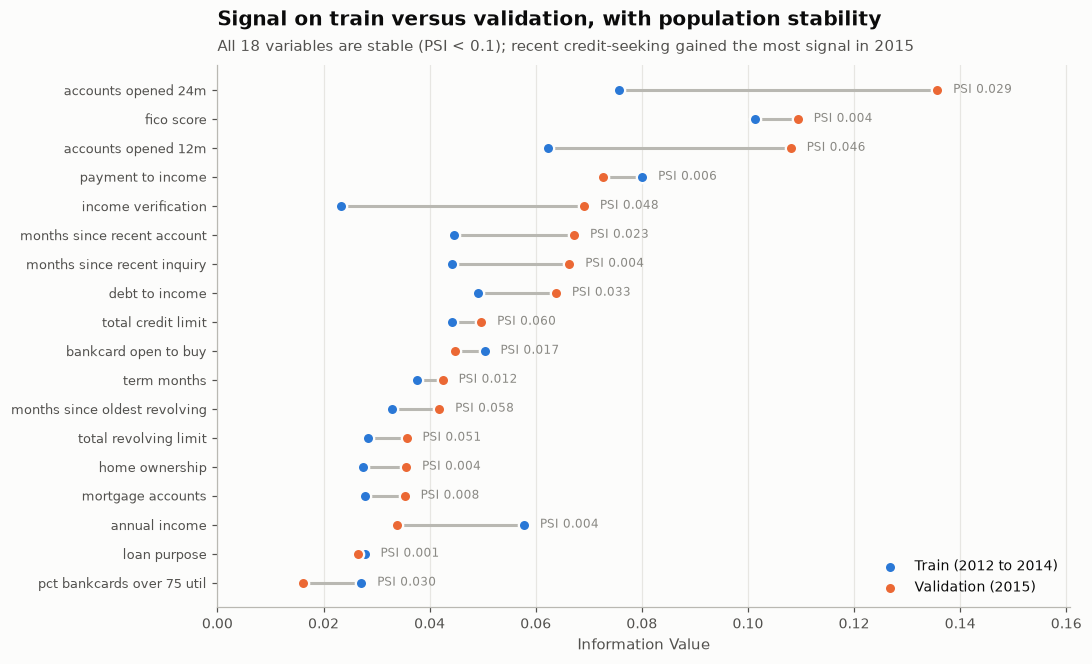

In [9]:
d = stab.sort_values("iv_validation")
fig, ax = plt.subplots(figsize=(10, 6.4))
yy = np.arange(len(d))
ax.hlines(yy, d[["iv_train", "iv_validation"]].min(axis=1), d[["iv_train", "iv_validation"]].max(axis=1),
          color=viz.NEUTRAL, lw=2)
ax.scatter(d.iv_train, yy, s=55, color=viz.BLUE, label="Train (2012 to 2014)", zorder=3, edgecolor=viz.SURFACE, linewidth=1.5)
ax.scatter(d.iv_validation, yy, s=55, color=viz.ORANGE, label="Validation (2015)", zorder=3, edgecolor=viz.SURFACE, linewidth=1.5)
ax.set_yticks(yy, d.variable.str.replace("_", " "), fontsize=8.5)
for y_, (p_, v_) in enumerate(zip(d.psi_train_vs_validation, d[["iv_train", "iv_validation"]].max(axis=1))):
    ax.text(v_ + 0.003, y_, f"PSI {p_:.3f}", va="center", fontsize=8, color=viz.INK_MUTED)
ax.set_xlim(0, d[["iv_train", "iv_validation"]].max().max() + 0.025)
ax.grid(axis="x", color=viz.GRID)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Information Value")
ax.legend(loc="lower right")
ax.set_title("Signal on train versus validation, with population stability")
viz.subtitle(ax, "All 18 variables are stable (PSI < 0.1); recent credit-seeking gained the most signal in 2015")
plt.show()

**What it means:** all 18 variables pass. Every PSI is below 0.06 (well inside the 0.1 "stable" limit) and every variable keeps its risk direction on 2015 data (trend consistency of 0.93 or higher). The screen still surfaces three things worth knowing:

- **Recent credit-seeking got stronger.** Accounts opened in the last 24 months nearly doubled its IV on 2015 data (0.076 to 0.136). This is the same loosening-cycle signal seen in notebook 04.
- **Income verification also strengthened** (0.023 to 0.069), consistent with Lending Club verifying more of its riskier applicants over time.
- **Two variables weakened:** annual income (0.058 to 0.034) and the share of bankcards above 75% utilisation (0.027 to 0.016). They stay in, but they are named in the model card as the first variables to watch in production.

## 6. Final scorecard variables

In [10]:
final_vars = stab.loc[stab.status != "Reject", "variable"].tolist()
summary = stab.set_index("variable").loc[final_vars, ["iv_train", "iv_validation", "psi_train_vs_validation", "status"]]
summary["bins"] = [len(binner.binnings_[v].table) for v in final_vars]
print(f"Final candidate set for the scorecard: {len(final_vars)} variables")
summary.style.format({"iv_train": "{:.4f}", "iv_validation": "{:.4f}", "psi_train_vs_validation": "{:.3f}"})

Final candidate set for the scorecard: 18 variables


,iv_train,iv_validation,psi_train_vs_validation,status,bins
variable,,,,,
fico_score,0.1014,0.1094,0.004,Stable,8
payment_to_income,0.0801,0.0727,0.006,Stable,8
accounts_opened_24m,0.0757,0.1357,0.029,Stable,8
accounts_opened_12m,0.0623,0.1081,0.046,Stable,6
annual_income,0.0578,0.0338,0.004,Stable,8
bankcard_open_to_buy,0.0503,0.0448,0.017,Stable,8
debt_to_income,0.0491,0.0638,0.033,Stable,8
months_since_recent_account,0.0446,0.0672,0.023,Stable,8
months_since_recent_inquiry,0.0441,0.0663,0.004,Stable,9


In [11]:
binner.save(MODELS_DIR / "woe_binning.json")
pd.Series(final_vars, name="variable").to_csv(MODELS_DIR / "scorecard_candidate_variables.csv", index=False)
print("Saved models/woe_binning.json and models/scorecard_candidate_variables.csv")

Saved models/woe_binning.json and models/scorecard_candidate_variables.csv


## 7. Summary

| Step | Variables |
|---|---|
| Candidates after cleaning | 47 |
| Information Value of at least 0.02 | 24 |
| After removing redundant pairs (WoE correlation > 0.7) | 18 |
| After stability screening (PSI < 0.25, trend consistency >= 0.8) | 18 |

Each surviving variable has bins a credit officer can read, a risk direction that makes business sense, measured stability on unseen data, and a clear reason for being in the model.

**Next:** notebook 06 fits the logistic regression scorecard on these WoE variables, converts it into points, and measures it against Lending Club's own grade on the 2016 out-of-time test.